# CNN 모델 비교 실험

## 1단계: 비교 환경 구성 및 모델 구조 확인


In [1]:
# 데이터 처리와 재현성 설정 및 모델 구성에 필요한 라이브러리 불러옴
import random
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from IPython.display import display
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout

# Python과 NumPy 및 TensorFlow 난수 시드 고정함
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# 기존 프로젝트 경로와 클래스 순서 고정함
project_dir = Path("D:/metal-surface-defect")
data_dir = project_dir / "data/NEU/NEU-CLS"
class_codes = ["Cr", "In", "Pa", "PS", "RS", "Sc"]
class_names = ["Crazing", "Inclusion", "Patches", "Pitted Surface", "Rolled-in Scale", "Scratches"]
class_to_label = {code: label for label, code in enumerate(class_codes)}
print("TensorFlow:", tf.__version__, "/ NumPy:", np.__version__, "/ scikit-learn:", sklearn.__version__)
display(pd.DataFrame({"라벨": range(6), "코드": class_codes, "클래스": class_names}))

TensorFlow: 2.21.0 / NumPy: 2.5.4 / scikit-learn: 1.9.1


,라벨,코드,클래스
0,0,Cr,Crazing
1,1,In,Inclusion
2,2,Pa,Patches
3,3,PS,Pitted Surface
4,4,RS,Rolled-in Scale
5,5,Sc,Scratches


### 데이터 분할 재현

- 기존 파일 정렬·라벨 순서·계층화 분할 재현함
- Train 1,260장 / Validation 270장
- 현재 원본 코드 기준 파일 목록·순서 일치함
- 과거 분할 목록 없음: 과거 파일 내용의 동일성 확인에는 한계 있음
- Test 270장: 경로만 유지, 이미지 미사용


In [2]:
# 기존 코드와 동일하게 클래스별 파일 번호를 숫자 순서로 정렬함
image_paths = []
for code in class_codes:
    image_paths.extend(sorted(
        data_dir.glob(f"{code}_*.bmp"),
        key=lambda path: int(path.stem.split("_")[1])
    ))

# 기존 파일명 접두어 규칙과 int64 자료형으로 분할용 라벨 구성함
y = np.array([class_to_label[path.stem.split("_")[0]] for path in image_paths], dtype=np.int64)

# 원본과 동일한 입력 순서와 인자로 Train 70% 및 나머지 30% 분할함
image_indices = np.arange(len(y))
train_indices, remaining_indices = train_test_split(
    image_indices, test_size=0.30, random_state=42, stratify=y
)

# 원본과 동일하게 나머지 인덱스를 Validation과 Test로 절반씩 분할함
val_indices, test_indices = train_test_split(
    remaining_indices, test_size=0.50, random_state=42, stratify=y[remaining_indices]
)

# 원본 파일 경로를 같은 인덱스로 선택하여 분할 목록 보관함
train_paths = [image_paths[i] for i in train_indices]
val_paths = [image_paths[i] for i in val_indices]
test_paths = [image_paths[i] for i in test_indices]

In [3]:
# 기준 Notebook 코드와 분할 라이브러리 버전이 변경되지 않았는지 확인함
with (project_dir / "metal_defect.ipynb").open(encoding="utf-8") as file:
    original_notebook = json.load(file)
reference_source_hashes = ['ecb6d5d23d0a1627e723161b46dd38e3a622f60e23cd1a22988ac705d8cf2775', 'f2be735184bdfb714cee649aa5d30f3d3f3353fff2cf8dbafaa02a5910f7e4ba']
current_source_hashes = [
    hashlib.sha256("".join(original_notebook["cells"][i]["source"]).encode()).hexdigest()
    for i in [15, 17]
]
assert current_source_hashes == reference_source_hashes, "기준 분할 코드 변경됨"
assert sklearn.__version__ == '1.9.1', "분할 라이브러리 버전 달라짐"

# 원본 코드를 독립 실행해 얻은 파일 목록 해시와 순서까지 비교함
reference_split_hashes = {'train': 'ed8ffafb9518e1f64af8690dabba817bf8865d70770bebe8f91b75d9af22260f', 'val': '275cac8910a0de14cd58eb1a69fcb68a3b3d70382b51596c53ecdcee58801f69', 'test': 'dab02d0c9de683d5aa3948526592f091637505e15dbb0e4329fa90117a3e4ec7'}
split_paths = {"train": train_paths, "val": val_paths, "test": test_paths}
split_hashes = {
    name: hashlib.sha256("\n".join(path.relative_to(data_dir).as_posix() for path in paths).encode()).hexdigest()
    for name, paths in split_paths.items()
}
assert split_hashes == reference_split_hashes, "기존 코드 기준 파일별 분할과 불일치함"
assert (len(train_paths), len(val_paths), len(test_paths)) == (1260, 270, 270)

# 세 분할 사이에 같은 원본 파일이 중복되지 않는지 확인함
overlap = bool(set(train_paths) & set(val_paths) or set(train_paths) & set(test_paths) or set(val_paths) & set(test_paths))
assert not overlap, "분할 간 원본 파일 중복됨"
display(pd.DataFrame({
    "분할": ["Train", "Validation", "Test (경로만 유지)"],
    "파일 수": [len(train_paths), len(val_paths), len(test_paths)],
    "기준 파일 목록·순서 일치": [split_hashes[name] == reference_split_hashes[name] for name in split_paths],
}))
print("세트 간 파일 중복:", overlap)

세트 간 파일 중복: False


,분할,파일 수,기준 파일 목록·순서 일치
0,Train,1260,True
1,Validation,270,True
2,Test (경로만 유지),270,True


### 학습·검증 이미지 전처리

- 200×200 흑백 / `float32` / 0~1 정규화
- 입력 형태: `(200, 200, 1)`


In [4]:
# 학습 및 검증 이미지에 동일한 원본 전처리 순서 적용함
image_arrays = {}
for name, paths in [("train", train_paths), ("val", val_paths)]:
    images = []
    for path in paths:
        with Image.open(path) as image:
            images.append(np.array(image.convert("L")))
    X_raw = np.array(images, dtype=np.uint8)
    X = X_raw.astype(np.float32)
    X /= 255.0
    image_arrays[name] = X[..., np.newaxis]
del images, X_raw, X

# 기존 분할 인덱스로 학습과 검증 라벨 선택함
X_train, y_train = image_arrays["train"], y[train_indices]
X_val, y_val = image_arrays["val"], y[val_indices]
print("X_train:", X_train.shape, "/ y_train:", y_train.shape)
print("X_val:", X_val.shape, "/ y_val:", y_val.shape)
print("자료형:", X_train.dtype, "/ 학습 픽셀 범위:", float(X_train.min()), "~", float(X_train.max()))
print("검증 픽셀 범위:", float(X_val.min()), "~", float(X_val.max()))

X_train: (1260, 200, 200, 1) / y_train: (1260,)
X_val: (270, 200, 200, 1) / y_val: (270,)
자료형: float32 / 학습 픽셀 범위: 0.0 ~ 1.0
검증 픽셀 범위: 0.0 ~ 1.0


### Baseline CNN 구조 확인

- 모델 가중치: **5,213,126개**
- `summary()` Total params에 Adam 상태 포함됨
- 구조 비교 시 옵티마이저 상태 제외함


In [5]:
# 저장된 모델 정보와 기존 학습 완료 모델을 그대로 불러옴
with (project_dir / "models/model_info.json").open(encoding="utf-8") as file:
    model_info = json.load(file)
baseline_model = tf.keras.models.load_model(project_dir / "models/cnn_model.keras")

# 입력과 출력 및 실제 모델 파라미터 수 확인함
print("Baseline 입력 형태:", baseline_model.input_shape)
print("Baseline 출력 형태:", baseline_model.output_shape)
baseline_params = baseline_model.count_params()
print("Baseline 전체 파라미터:", baseline_params)
assert baseline_params == 5_213_126, "기록된 Baseline 파라미터 수와 불일치함"
assert baseline_model.input_shape == (None, 200, 200, 1) and baseline_model.output_shape == (None, 6)
assert [(item["code"], item["name"]) for item in model_info["classes"]] == list(zip(class_codes, class_names))
baseline_model.summary()

Baseline 입력 형태: (None, 200, 200, 1)
Baseline 출력 형태: (None, 6)
Baseline 전체 파라미터: 5213126
Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 200, 200, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 50

### GAP CNN 구성 및 구조 확인

- Flatten → GlobalAveragePooling2D 교체함
- 나머지 계층 유지함
- 새 가중치로 초기화함: 기존 가중치 복사 없음


In [6]:
# 같은 입력과 합성곱 및 풀링 계층으로 새 모델 구성함
gap_model = Sequential([
    Input(shape=(200, 200, 1)),
    # 32개 필터로 특징 추출하고 공간 크기 축소함
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    # 64개 필터로 특징 추출하고 공간 크기 축소함
    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    # 마지막 합성곱 계층의 이름과 128개 필터 유지함
    Conv2D(128, (3, 3), activation="relu", padding="same", name="last_conv"),
    MaxPooling2D((2, 2)),
    # Flatten 대신 채널별 공간 평균으로 특징 벡터 구성함
    GlobalAveragePooling2D(),
    # 기존과 동일한 분류 계층과 Dropout 비율 유지함
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(6, activation="softmax"),
])

# 컴파일 및 학습 없이 개선 모델 구조 출력함
gap_model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 200, 200, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼─────────────────────

In [7]:
# 가중치 배열 크기로 두 모델의 학습 가능한 파라미터 수 계산함
models = [baseline_model, gap_model]
trainable_params = [sum(int(np.prod(weight.shape)) for weight in model.trainable_weights) for model in models]
comparison = pd.DataFrame({
    "모델": ["Baseline CNN", "GAP CNN"],
    "입력 형태": [str(model.input_shape[1:]) for model in models],
    "Conv2D 필터": [str([layer.filters for layer in model.layers if isinstance(layer, Conv2D)]) for model in models],
    "특징 집계": ["Flatten", "GlobalAveragePooling2D"],
    "Dense 입력 특징 수": [int(model.layers[7].kernel.shape[0]) for model in models],
    "Dense 유닛": [str([layer.units for layer in model.layers if isinstance(layer, Dense)]) for model in models],
    "전체 파라미터": [model.count_params() for model in models],
    "학습 가능 파라미터": trainable_params,
})
display(comparison)

# 전체 모델 가중치 기준 파라미터 감소량과 감소율 계산함
gap_params = gap_model.count_params()
parameter_reduction = baseline_params - gap_params
reduction_rate = parameter_reduction / baseline_params * 100
print(f"파라미터 감소량: {parameter_reduction:,}개")
print(f"파라미터 감소율: {reduction_rate:.4f}%")

파라미터 감소량: 5,111,808개
파라미터 감소율: 98.0565%


,모델,입력 형태,Conv2D 필터,특징 집계,Dense 입력 특징 수,Dense 유닛,전체 파라미터,학습 가능 파라미터
0,Baseline CNN,"(200, 200, 1)","[32, 64, 128]",Flatten,80000,"[64, 6]",5213126,5213126
1,GAP CNN,"(200, 200, 1)","[32, 64, 128]",GlobalAveragePooling2D,128,"[64, 6]",101318,101318


### 모델 구조 비교 결과

- Dense 입력 특징: 80,000개 → 128개
- GAP 모델 파라미터: **101,318개**
- 파라미터 감소가 정확도 향상을 보장하지 않음


## 2단계: GAP CNN 학습 및 Validation 성능 평가

- Adam / 학습률 0.001 / Sparse Categorical Crossentropy
- 배치 크기 32 / 최대 20 Epoch
- EarlyStopping: `val_loss`, `patience=4`, `restore_best_weights=True`


In [8]:
# 학습 시간 측정과 검증 지표 및 그래프 기능 불러옴
import time
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

# 기존 CNN과 동일한 옵티마이저 및 손실 함수로 GAP 모델만 컴파일함
gap_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# 검증 손실이 4 Epoch 동안 개선되지 않으면 종료하고 최적 가중치 복원함
gap_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

In [9]:
# GAP 모델의 실제 학습 소요 시간 측정 시작함
gap_training_start = time.perf_counter()

# 이미 준비된 학습 및 검증 배열만 사용하여 GAP CNN 학습함
gap_history = gap_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[gap_early_stopping],
    verbose=2,
)

# 학습 종료까지 걸린 시간과 실행 및 최적 Epoch 기록함
gap_training_seconds = time.perf_counter() - gap_training_start
gap_epochs = np.arange(1, len(gap_history.history["loss"]) + 1)
gap_best_epoch = int(np.argmin(gap_history.history["val_loss"])) + 1
print(f"학습 시간: {gap_training_seconds:.2f}초")
print("실행 Epoch:", len(gap_epochs), "/ 최적 Epoch:", gap_best_epoch)
print("EarlyStopping 조기 종료:", gap_early_stopping.stopped_epoch > 0)

Epoch 1/20
40/40 - 28s - 704ms/step - accuracy: 0.1960 - loss: 1.7701 - val_accuracy: 0.1667 - val_loss: 1.7260
Epoch 2/20
40/40 - 22s - 550ms/step - accuracy: 0.3079 - loss: 1.5815 - val_accuracy: 0.3519 - val_loss: 1.3366
Epoch 3/20
40/40 - 23s - 566ms/step - accuracy: 0.4579 - loss: 1.2070 - val_accuracy: 0.6407 - val_loss: 0.9565
Epoch 4/20
40/40 - 29s - 719ms/step - accuracy: 0.5643 - loss: 1.0070 - val_accuracy: 0.6148 - val_loss: 0.9635
Epoch 5/20
40/40 - 37s - 926ms/step - accuracy: 0.6476 - loss: 0.8671 - val_accuracy: 0.7222 - val_loss: 0.6543
Epoch 6/20
40/40 - 28s - 688ms/step - accuracy: 0.6921 - loss: 0.7785 - val_accuracy: 0.8148 - val_loss: 0.5749
Epoch 7/20
40/40 - 32s - 793ms/step - accuracy: 0.7619 - loss: 0.6517 - val_accuracy: 0.8407 - val_loss: 0.4889
Epoch 8/20
40/40 - 29s - 727ms/step - accuracy: 0.7492 - loss: 0.6269 - val_accuracy: 0.8333 - val_loss: 0.4649
Epoch 9/20
40/40 - 29s - 719ms/step - accuracy: 0.8032 - loss: 0.5212 - val_accuracy: 0.8519 - val_loss:

In [10]:
# 실제 학습 이력을 Epoch별 정확도와 손실 표로 정리함
gap_history_table = pd.DataFrame({
    "Epoch": gap_epochs,
    "Train Accuracy": gap_history.history["accuracy"],
    "Validation Accuracy": gap_history.history["val_accuracy"],
    "Train Loss": gap_history.history["loss"],
    "Validation Loss": gap_history.history["val_loss"],
})
display(gap_history_table)

,Epoch,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,1,0.196032,0.166667,1.770123,1.726047
1,2,0.307937,0.351852,1.581480,1.336648
2,3,0.457936,0.640741,1.207031,0.956484
3,4,0.564286,0.614815,1.006969,0.963481
4,5,0.647619,0.722222,0.867124,0.654329
5,6,0.692064,0.814815,0.778545,0.574921
6,7,0.761905,0.840741,0.651666,0.488876
7,8,0.749206,0.833333,0.626861,0.464880
8,9,0.803175,0.851852,0.521239,0.401339
9,10,0.780952,0.855556,0.555142,0.405544


### GAP CNN 학습 이력


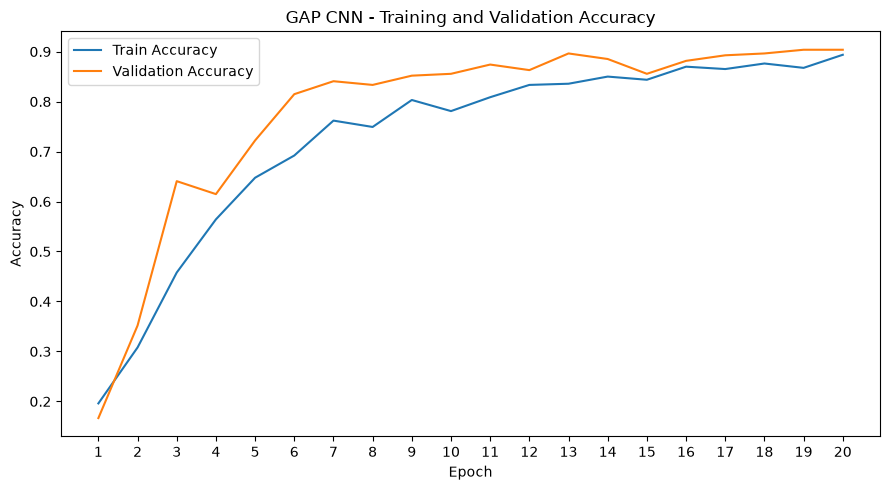

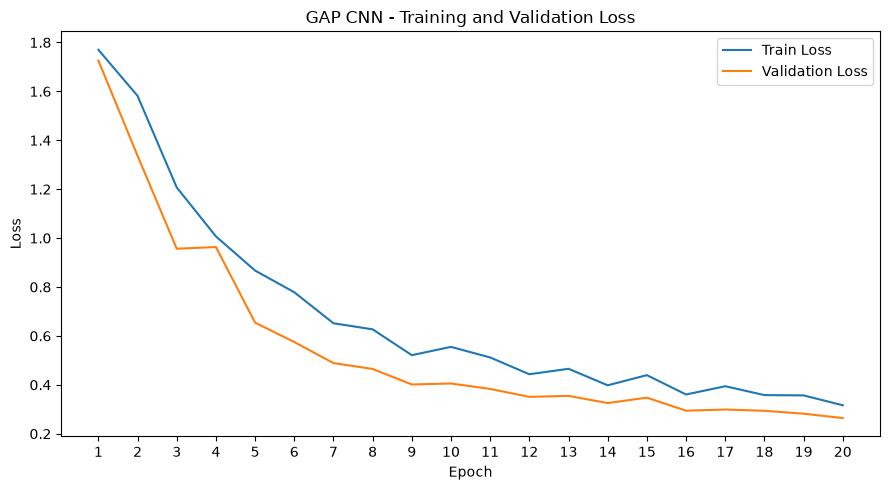

In [11]:
# GAP 학습 그래프 경로를 지정하고 기존 PNG 덮어쓰기 방지함
gap_figure_dir = project_dir / "outputs/figures"
gap_accuracy_path = gap_figure_dir / "gap_training_accuracy.png"
gap_loss_path = gap_figure_dir / "gap_training_loss.png"
assert not gap_accuracy_path.exists() and not gap_loss_path.exists(), "동일 이름의 학습 그래프가 이미 존재함"

# 실제 Train/Validation 정확도를 같은 그래프에 표시함
plt.figure(figsize=(9, 5))
plt.plot(gap_epochs, gap_history.history["accuracy"], label="Train Accuracy")
plt.plot(gap_epochs, gap_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("GAP CNN - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(gap_epochs)
plt.legend()
plt.tight_layout()
plt.savefig(gap_accuracy_path, dpi=150, bbox_inches="tight")
plt.show()

# 실제 Train/Validation 손실을 같은 그래프에 표시함
plt.figure(figsize=(9, 5))
plt.plot(gap_epochs, gap_history.history["loss"], label="Train Loss")
plt.plot(gap_epochs, gap_history.history["val_loss"], label="Validation Loss")
plt.title("GAP CNN - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(gap_epochs)
plt.legend()
plt.tight_layout()
plt.savefig(gap_loss_path, dpi=150, bbox_inches="tight")
plt.show()

### 학습 결과 및 Validation 평가

- 정확도 전반적 상승, 손실 감소함: 일부 Epoch 변동 있음
- 실행 20 Epoch / 최적 Epoch 20 / 조기 종료 없음
- Validation Accuracy **90.37%** / Macro F1 **0.904352** / Loss **0.264013**
- 해당 곡선만으로 과적합이 없다고 단정할 수 없음


In [12]:
# 최적 가중치로 복원된 GAP 모델의 검증 손실과 정확도 계산함
gap_val_loss, gap_evaluated_accuracy = gap_model.evaluate(X_val, y_val, verbose=0)

# 검증 이미지의 실제 Softmax 출력에서 예측 라벨 추출함
gap_val_probabilities = gap_model.predict(X_val, verbose=0)
gap_val_predictions = np.argmax(gap_val_probabilities, axis=1)
gap_val_accuracy = accuracy_score(y_val, gap_val_predictions)

# 여섯 클래스를 동일한 비중으로 평가하는 Macro 지표 계산함
gap_macro_precision, gap_macro_recall, gap_macro_f1, _ = precision_recall_fscore_support(
    y_val, gap_val_predictions, labels=np.arange(6), average="macro", zero_division=0
)
gap_validation_metrics = pd.DataFrame({
    "지표": ["Validation Loss", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"],
    "결과": [gap_val_loss, gap_val_accuracy, gap_macro_precision, gap_macro_recall, gap_macro_f1],
})
display(gap_validation_metrics)

# 고정된 클래스 순서로 클래스별 지표와 실제 클래스 기준 오분류 수 집계함
gap_report = classification_report(
    y_val, gap_val_predictions, labels=np.arange(6), target_names=class_names,
    output_dict=True, zero_division=0,
)
gap_class_metrics = pd.DataFrame(gap_report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
gap_class_metrics["support"] = gap_class_metrics["support"].astype(int)
gap_class_metrics["misclassified"] = np.bincount(y_val[y_val != gap_val_predictions], minlength=6)
gap_class_metrics.index.name = "Class"
display(gap_class_metrics)

,지표,결과
0,Validation Loss,0.264013
1,Accuracy,0.903704
2,Macro Precision,0.908494
3,Macro Recall,0.903704
4,Macro F1-score,0.904352


,precision,recall,f1-score,support,misclassified
Class,,,,,
Crazing,0.936170,0.977778,0.956522,45,1
Inclusion,0.754717,0.888889,0.816327,45,5
Patches,0.976744,0.933333,0.954545,45,3
Pitted Surface,0.833333,0.777778,0.804598,45,10
Rolled-in Scale,1.000000,1.000000,1.000000,45,0
Scratches,0.950000,0.844444,0.894118,45,7


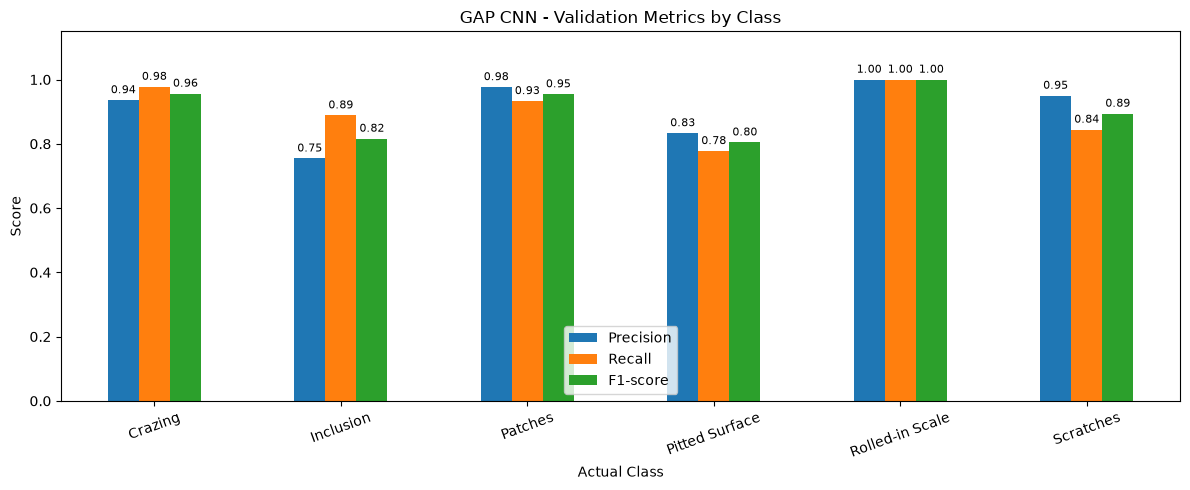

In [13]:
# 클래스별 검증 지표 그래프의 기존 파일 덮어쓰기 방지함
gap_class_metrics_path = gap_figure_dir / "gap_validation_class_metrics.png"
assert not gap_class_metrics_path.exists(), "동일 이름의 클래스별 검증 그래프가 이미 존재함"

# 실제 클래스별 Precision과 Recall 및 F1을 그룹 막대로 비교함
fig, ax = plt.subplots(figsize=(12, 5))
gap_class_metrics[["precision", "recall", "f1-score"]].plot.bar(ax=ax, rot=20)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.set(title="GAP CNN - Validation Metrics by Class", xlabel="Actual Class", ylabel="Score", ylim=(0, 1.15))
ax.legend(["Precision", "Recall", "F1-score"])
plt.tight_layout()
plt.savefig(gap_class_metrics_path, dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# 기존 CNN과 구분되는 새 파일명으로 학습된 GAP 모델 저장함
gap_model_path = project_dir / "models/cnn_gap_model.keras"
assert not gap_model_path.exists(), "동일 이름의 GAP 모델이 이미 존재함"
gap_model.save(gap_model_path)
print("GAP 모델 저장 경로:", gap_model_path)

GAP 모델 저장 경로: D:\metal-surface-defect\models\cnn_gap_model.keras


### GAP CNN 실험 결과

- 저장 모델: `models/cnn_gap_model.keras`
- 실제 학습 기록 및 최적 가중치의 검증 결과


In [15]:
# 실제 학습 시간과 Epoch 및 복원 모델의 검증 지표를 최종 표로 정리함
gap_experiment_summary = pd.DataFrame({
    "항목": ["파라미터 수", "학습 시간 (초)", "실행 Epoch", "최적 Epoch", "Validation Accuracy", "Validation Macro F1", "Validation Loss"],
    "GAP CNN 결과": [
        gap_model.count_params(), gap_training_seconds, len(gap_epochs), gap_best_epoch,
        gap_val_accuracy, gap_macro_f1, gap_val_loss,
    ],
})
display(gap_experiment_summary)

,항목,GAP CNN 결과
0,파라미터 수,101318.000000
1,학습 시간 (초),565.982739
2,실행 Epoch,20.000000
3,최적 Epoch,20.000000
4,Validation Accuracy,0.903704
5,Validation Macro F1,0.904352
6,Validation Loss,0.264013


## 3단계: Baseline CNN과 GAP CNN의 Validation 비교

- 동일한 Validation 270장 / 배치 크기 32
- 추가 학습·테스트 평가 없음


In [16]:
# 동일 조건 평가와 기록 조회 및 그래프 작성에 필요한 기능 불러옴
import re
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, classification_report, confusion_matrix

# 기존 가중치와 저장된 학습 설정을 그대로 로드함
comparison_models = {
    "Baseline CNN": tf.keras.models.load_model(project_dir / "models/cnn_model.keras"),
    "GAP CNN": tf.keras.models.load_model(project_dir / "models/cnn_gap_model.keras"),
}
print("공통 Validation 배열:", X_val.shape, "/ 라벨:", y_val.shape)
display(pd.Series(np.bincount(y_val, minlength=6), index=class_names, name="Validation 이미지 수"))

# 기존 Notebook의 실제 학습 출력과 모델 정보만 읽어 참고 기록 보관함
with (project_dir / "metal_defect.ipynb").open(encoding="utf-8") as file:
    baseline_notebook = json.load(file)
with (project_dir / "model_comparison.ipynb").open(encoding="utf-8") as file:
    comparison_notebook = json.load(file)
with (project_dir / "models/model_info.json").open(encoding="utf-8") as file:
    baseline_info = json.load(file)
baseline_training_text = "".join("".join(o.get("text", [])) for o in baseline_notebook["cells"][28]["outputs"])
gap_training_text = "".join("".join(o.get("text", [])) for o in comparison_notebook["cells"][15]["outputs"])
gap_summary_text = "\n".join(o.get("data", {}).get("text/plain", "") for o in comparison_notebook["cells"][24]["outputs"])
baseline_training_seconds = float(re.search(r"전체 학습 소요 시간:\s*([0-9.]+)초", baseline_training_text).group(1))
gap_training_seconds_recorded = float(re.search(r"학습 시간 \(초\)\s+([0-9.]+)", gap_summary_text).group(1))
gap_epochs_recorded, gap_best_epoch_recorded = map(int, re.search(r"실행 Epoch:\s*(\d+) / 최적 Epoch:\s*(\d+)", gap_training_text).groups())

공통 Validation 배열: (270, 200, 200, 1) / 라벨: (270,)


Crazing            45
Inclusion          45
Patches            45
Pitted Surface     45
Rolled-in Scale    45
Scratches          45
Name: Validation 이미지 수, dtype: int64

In [17]:
# 두 모델에 정확히 같은 검증 배열과 배치 크기를 적용함
comparison_metrics = {}
comparison_class_metrics = {}
comparison_confusions = {}
comparison_predictions = {}
for name, comparison_model in comparison_models.items():
    loss, evaluated_accuracy = comparison_model.evaluate(X_val, y_val, batch_size=32, verbose=0)
    probabilities = comparison_model.predict(X_val, batch_size=32, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    comparison_predictions[name] = predictions

    # 실제 예측으로 전체 정확도와 Macro 및 Weighted 지표 계산함
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_val, predictions, labels=np.arange(6), average="macro", zero_division=0
    )
    comparison_metrics[name] = {
        "Accuracy": accuracy_score(y_val, predictions), "Loss": float(loss),
        "Macro Precision": precision, "Macro Recall": recall, "Macro F1": macro_f1,
        "Weighted F1": f1_score(y_val, predictions, labels=np.arange(6), average="weighted", zero_division=0),
        "Misclassified": int(np.count_nonzero(y_val != predictions)),
    }

    # 동일한 클래스 순서로 클래스별 지표와 혼동행렬 계산함
    report = classification_report(y_val, predictions, labels=np.arange(6), target_names=class_names, output_dict=True, zero_division=0)
    class_metrics = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    class_metrics["support"] = class_metrics["support"].astype(int)
    class_metrics["misclassified"] = np.bincount(y_val[y_val != predictions], minlength=6)
    comparison_class_metrics[name] = class_metrics
    comparison_confusions[name] = confusion_matrix(y_val, predictions, labels=np.arange(6))

# 동일 평가 코드로 계산한 전체 지표와 클래스별 상세 지표 출력함
comparison_metrics_table = pd.DataFrame(comparison_metrics).T
comparison_metrics_table["Misclassified"] = comparison_metrics_table["Misclassified"].astype(int)
display(comparison_metrics_table)
display(pd.concat(comparison_class_metrics, names=["Model", "Actual Class"]))

,Accuracy,Loss,Macro Precision,Macro Recall,Macro F1,Weighted F1,Misclassified
Baseline CNN,0.944444,0.185013,0.948591,0.944444,0.944891,0.944891,15
GAP CNN,0.903704,0.264013,0.908494,0.903704,0.904352,0.904352,26


precision    recall  ...  support  misclassified
Model        Actual Class                          ...                        
Baseline CNN Crazing           1.000000  0.977778  ...       45              1
             Inclusion         0.886364  0.866667  ...       45              6
             Patches           0.978261  1.000000  ...       45              0
             Pitted Surface    0.826923  0.955556  ...       45              2
             Rolled-in Scale   1.000000  1.000000  ...       45              0
             Scratches         1.000000  0.866667  ...       45              6
GAP CNN      Crazing           0.936170  0.977778  ...       45              1
             Inclusion         0.754717  0.888889  ...       45              5
             Patches           0.976744  0.933333  ...       45              3
             Pitted Surface    0.833333  0.777778  ...       45             10
             Rolled-in Scale   1.000000  1.000000  ...       45              0
             Scratches         0.950000  0.844444  ...       45              7

[12 rows x 5 columns]

In [18]:
# 이전 실제 기록과 재계산 결과를 같은 정밀도로 비교함
recorded_values = {
    "Baseline CNN": {"Accuracy": baseline_info["validation_accuracy"], "Loss": baseline_info["validation_loss"], "Macro F1": baseline_info["validation_macro_f1"]},
    "GAP CNN": {
        "Accuracy": float(re.search(r"Validation Accuracy\s+([0-9.]+)", gap_summary_text).group(1)),
        "Loss": float(re.search(r"Validation Loss\s+([0-9.]+)", gap_summary_text).group(1)),
        "Macro F1": float(re.search(r"Validation Macro F1\s+([0-9.]+)", gap_summary_text).group(1)),
    },
}
record_checks = []
for name in comparison_models:
    for metric in ["Accuracy", "Loss", "Macro F1"]:
        old_value = recorded_values[name][metric]
        new_value = comparison_metrics[name][metric]
        record_checks.append({"모델": name, "지표": metric, "기존 기록": old_value, "재계산": new_value,
                              "차이": new_value - old_value, "오차 범위 내 일치": bool(np.isclose(new_value, old_value, atol=1e-6, rtol=0))})
record_checks_table = pd.DataFrame(record_checks)
display(record_checks_table)
assert record_checks_table["오차 범위 내 일치"].all(), "기존 기록과 재계산 차이의 원인 확인 필요함"

# 옵티마이저 상태를 제외한 모델 가중치 수로 구조와 효율 비교함
baseline_count = comparison_models["Baseline CNN"].count_params()
gap_count = comparison_models["GAP CNN"].count_params()
comparison_reduction = (baseline_count - gap_count) / baseline_count * 100
structure_comparison = pd.DataFrame({
    "Baseline CNN": ["Flatten", baseline_count, "기준", baseline_training_seconds,
                     baseline_info["training_epochs"], baseline_info["best_epoch"],
                     comparison_metrics["Baseline CNN"]["Accuracy"], comparison_metrics["Baseline CNN"]["Macro F1"], comparison_metrics["Baseline CNN"]["Loss"]],
    "GAP CNN": ["GlobalAveragePooling2D", gap_count, f"{comparison_reduction:.4f}%", gap_training_seconds_recorded,
                gap_epochs_recorded, gap_best_epoch_recorded,
                comparison_metrics["GAP CNN"]["Accuracy"], comparison_metrics["GAP CNN"]["Macro F1"], comparison_metrics["GAP CNN"]["Loss"]],
}, index=["모델 구조", "파라미터 수", "파라미터 감소율", "학습 시간 (초, 참고)", "실행 Epoch", "최적 Epoch", "Validation Accuracy", "Validation Macro F1", "Validation Loss"])
display(structure_comparison)

,모델,지표,기존 기록,재계산,차이,오차 범위 내 일치
0,Baseline CNN,Accuracy,0.944444,0.944444,2.649095e-08,True
1,Baseline CNN,Loss,0.185013,0.185013,0.000000e+00,True
2,Baseline CNN,Macro F1,0.944891,0.944891,0.000000e+00,True
3,GAP CNN,Accuracy,0.903704,0.903704,-2.962963e-07,True
4,GAP CNN,Loss,0.264013,0.264013,2.606030e-07,True
5,GAP CNN,Macro F1,0.904352,0.904352,-4.879173e-07,True


,Baseline CNN,GAP CNN
모델 구조,Flatten,GlobalAveragePooling2D
파라미터 수,5213126,101318
파라미터 감소율,기준,98.0565%
"학습 시간 (초, 참고)",664.35,565.982739
실행 Epoch,20,20
최적 Epoch,17,20
Validation Accuracy,0.944444,0.903704
Validation Macro F1,0.944891,0.904352
Validation Loss,0.185013,0.264013


### 전체 검증 성능 및 파라미터 비교

- 재계산한 Accuracy·Loss·Macro F1이 기존 기록과 오차 범위 내 일치함


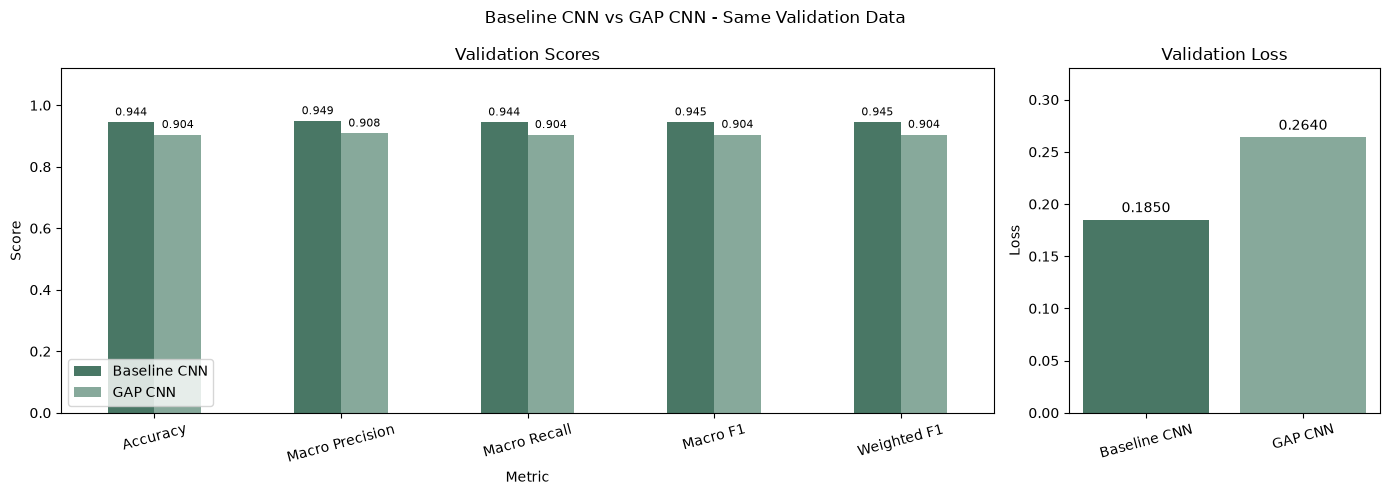

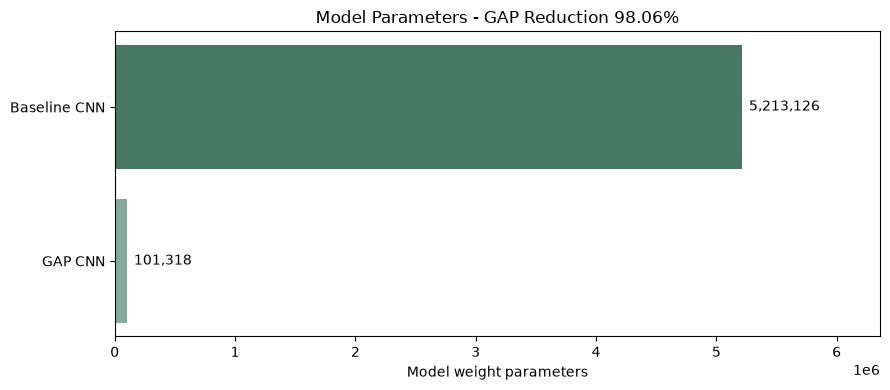

In [22]:
# 새 비교 그래프 경로를 지정하고 기존 PNG 덮어쓰기 방지함
comparison_figure_dir = project_dir / "outputs/figures"
comparison_png_names = ["model_comparison_metrics.png", "model_comparison_class_recall.png", "model_comparison_confusion_matrix.png", "model_comparison_parameters.png"]
assert all(not (comparison_figure_dir / name).exists() for name in comparison_png_names), "동일 이름의 비교 PNG가 이미 존재함"
comparison_colors = ["#497765", "#87A99B"]

# 전체 검증 지표와 손실을 분리된 축으로 비교함
score_columns = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 1]})
comparison_metrics_table[score_columns].T.plot.bar(ax=axes[0], color=comparison_colors, rot=15)
for bars in axes[0].containers:
    axes[0].bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
axes[0].set(title="Validation Scores", ylabel="Score", ylim=(0, 1.12))
axes[0].set_xlabel("Metric")
axes[0].legend(loc="lower left")
bars = axes[1].bar(comparison_metrics_table.index, comparison_metrics_table["Loss"], color=comparison_colors)
axes[1].bar_label(bars, fmt="%.4f", padding=3)
axes[1].set(title="Validation Loss", ylabel="Loss", ylim=(0, comparison_metrics_table["Loss"].max() * 1.25))
axes[1].tick_params(axis="x", labelrotation=15)
fig.suptitle("Baseline CNN vs GAP CNN - Same Validation Data")
plt.tight_layout()
plt.savefig(comparison_figure_dir / "model_comparison_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

# 실제 모델 파라미터 수와 감소율을 선형 축으로 표시함
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(["Baseline CNN", "GAP CNN"], [baseline_count, gap_count], color=comparison_colors)
ax.bar_label(bars, labels=[f"{baseline_count:,}", f"{gap_count:,}"], padding=5)
ax.set(title=f"Model Parameters - GAP Reduction {comparison_reduction:.2f}%", xlabel="Model weight parameters", xlim=(0, baseline_count * 1.22))
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(comparison_figure_dir / "model_comparison_parameters.png", dpi=150, bbox_inches="tight")
plt.show()

### 클래스별 Recall·F1 및 오분류 비교

- 변화량: GAP − Baseline
- Recall 차이 단위: 퍼센트포인트(%p)


,Baseline Recall,GAP Recall,Recall 변화 (%p),Baseline F1,GAP F1,F1 변화,Baseline 오분류,GAP 오분류
Crazing,0.977778,0.977778,0.000000,0.988764,0.956522,-0.032242,1.0,1.0
Inclusion,0.866667,0.888889,2.222222,0.876404,0.816327,-0.060078,6.0,5.0
Patches,1.000000,0.933333,-6.666667,0.989011,0.954545,-0.034466,0.0,3.0
Pitted Surface,0.955556,0.777778,-17.777778,0.886598,0.804598,-0.082000,2.0,10.0
Rolled-in Scale,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.0,0.0
Scratches,0.866667,0.844444,-2.222222,0.928571,0.894118,-0.034454,6.0,7.0


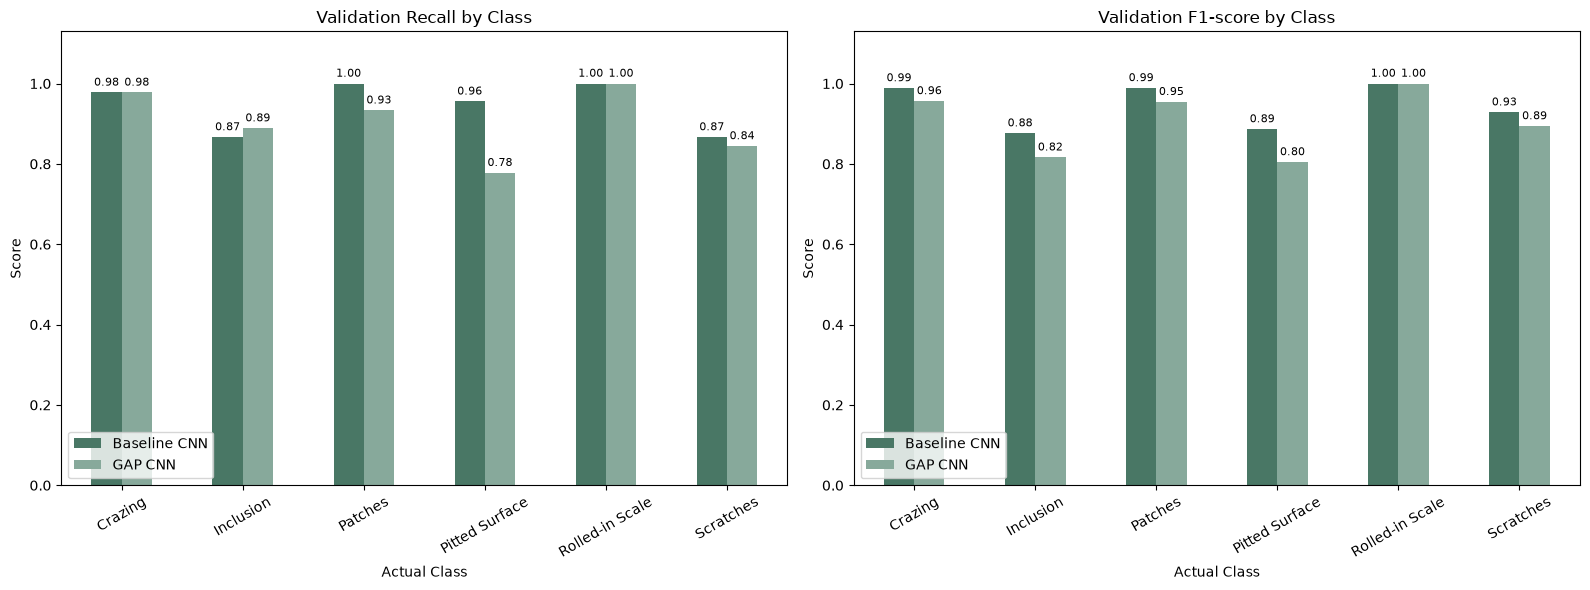

In [23]:
# 클래스별 Recall과 F1 및 오분류 차이를 실제 결과로 정리함
baseline_classes = comparison_class_metrics["Baseline CNN"]
gap_classes = comparison_class_metrics["GAP CNN"]
class_change_table = pd.DataFrame({
    "Baseline Recall": baseline_classes["recall"], "GAP Recall": gap_classes["recall"],
    "Recall 변화 (%p)": (gap_classes["recall"] - baseline_classes["recall"]) * 100,
    "Baseline F1": baseline_classes["f1-score"], "GAP F1": gap_classes["f1-score"],
    "F1 변화": gap_classes["f1-score"] - baseline_classes["f1-score"],
    "Baseline 오분류": baseline_classes["misclassified"], "GAP 오분류": gap_classes["misclassified"],
})
display(class_change_table)

# 클래스별 Recall과 F1을 같은 범위의 그룹 막대그래프로 표시함
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metric, title in zip(axes, ["recall", "f1-score"], ["Recall", "F1-score"]):
    values = pd.DataFrame({name: frame[metric] for name, frame in comparison_class_metrics.items()})
    values.plot.bar(ax=ax, color=comparison_colors, rot=30)
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=3)
    ax.legend(loc="lower left")
    ax.set(title=f"Validation {title} by Class", xlabel="Actual Class", ylabel="Score", ylim=(0, 1.13))
plt.tight_layout()
plt.savefig(comparison_figure_dir / "model_comparison_class_recall.png", dpi=150, bbox_inches="tight")
plt.show()

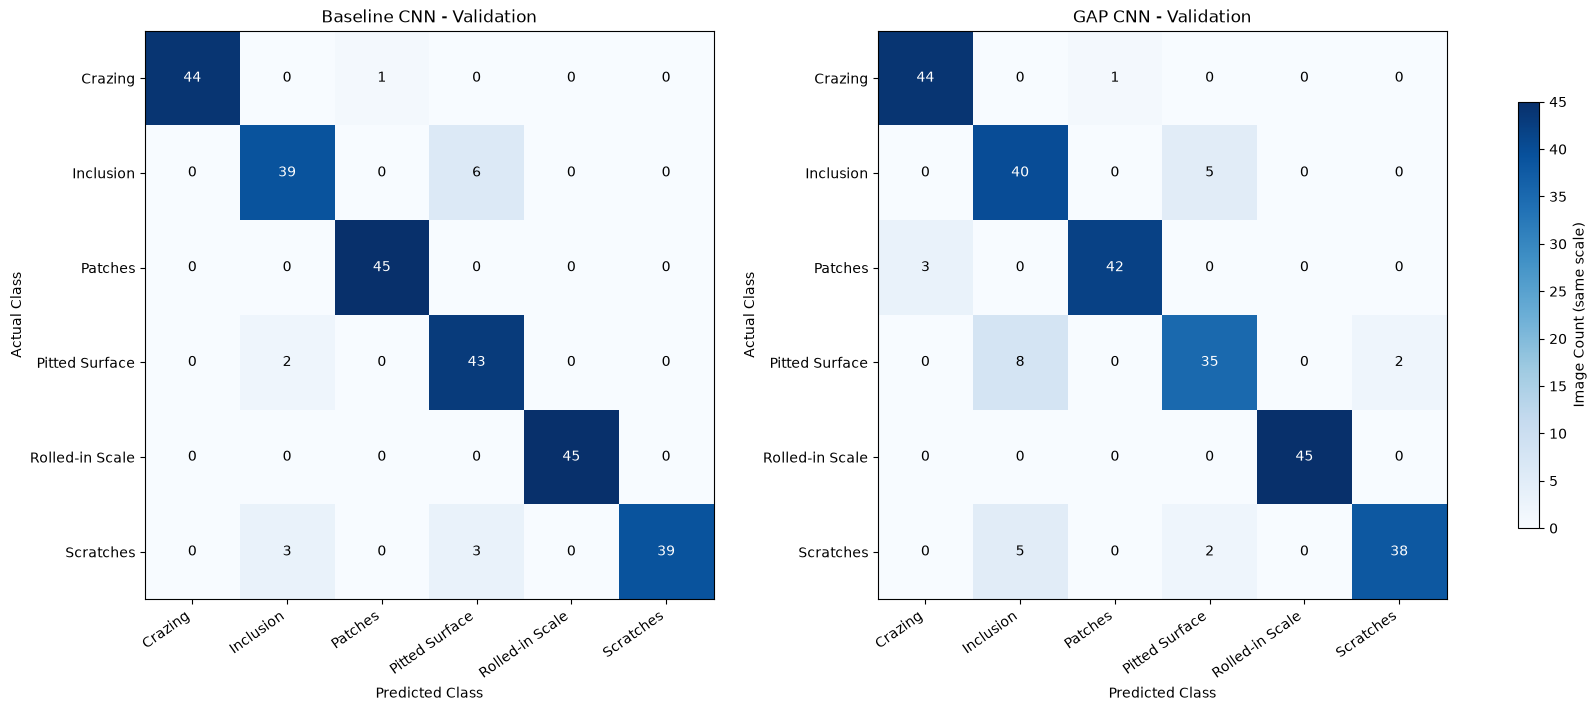

,모델,실제 클래스,예측 클래스,건수
1,Baseline CNN,Inclusion,Pitted Surface,6
3,Baseline CNN,Scratches,Inclusion,3
4,Baseline CNN,Scratches,Pitted Surface,3
2,Baseline CNN,Pitted Surface,Inclusion,2
0,Baseline CNN,Crazing,Patches,1
8,GAP CNN,Pitted Surface,Inclusion,8
6,GAP CNN,Inclusion,Pitted Surface,5
10,GAP CNN,Scratches,Inclusion,5
7,GAP CNN,Patches,Crazing,3
9,GAP CNN,Pitted Surface,Scratches,2


In [21]:
# 두 혼동행렬을 같은 클래스 순서와 색상 범위로 표시함
fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout="constrained")
for ax, (name, matrix) in zip(axes, comparison_confusions.items()):
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=45)
    for row in range(6):
        for col in range(6):
            ax.text(col, row, str(matrix[row, col]), ha="center", va="center", color="white" if matrix[row, col] > 22.5 else "black")
    ax.set_xticks(range(6), class_names, rotation=35, ha="right")
    ax.set_yticks(range(6), class_names)
    ax.set(title=f"{name} - Validation", xlabel="Predicted Class", ylabel="Actual Class")
fig.colorbar(image, ax=axes, shrink=0.75, label="Image Count (same scale)")
plt.savefig(comparison_figure_dir / "model_comparison_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 대각선을 제외한 실제 클래스에서 예측 클래스로의 혼동 건수 출력함
confusion_rows = []
for name, matrix in comparison_confusions.items():
    for actual, predicted in np.argwhere(matrix > 0):
        if actual != predicted:
            confusion_rows.append({"모델": name, "실제 클래스": class_names[actual], "예측 클래스": class_names[predicted], "건수": int(matrix[actual, predicted])})
confusion_pairs = pd.DataFrame(confusion_rows).sort_values(["모델", "건수"], ascending=[True, False])
display(confusion_pairs)

### 비교 결과 및 해석

- 파라미터: **5,213,126개 → 101,318개**, **98.0565% 감소**
- Validation Accuracy: **94.44% → 90.37%**
- Macro F1: **0.944891 → 0.904352**
- 오분류: **15장 → 26장**
- 경량화와 함께 전체 검증 성능 저하됨

- Inclusion Recall: **+2.22%p**, F1은 하락함
- Pitted Surface Recall: **−17.78%p**
- Scratches Recall: **−2.22%p**
- Pitted Surface → Inclusion: **2장 → 8장**
- Scratches → Inclusion: **3장 → 5장**

- 학습 시간: Baseline **664.35초** / GAP **565.98초**
- 실행 시점·환경 부하가 달라 순수한 구조별 속도 차이로 해석할 수 없음
- 단일 분할·각 1회 학습 결과임: 성능 차이를 GAP만의 영향으로 단정할 수 없음
- 테스트 성능·실제 배포 속도는 판단 범위에서 제외함
